# Machine Learning Lab 6 — Logistic Regression & KNN Classification

**Name:** Abdul Rafiu
**Student ID:** 023-24-0265  
**Section:** H  
**GitHub:** https://github.com/AbdulRafiu7/ML-lab-6
**Kaggle:** abrafay7
**Dataset:** Telco Customer Churn  
**Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn


## Setup: Imports

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay)

pd.set_option('display.max_columns', None)
np.random.seed(42)


## Part 1 — Problem Definition & Dataset Verification

We continue with the same **Telco Customer Churn** dataset used in Labs 2–4. The task is
binary classification: predict whether a customer will churn (`Churn` = Yes/No).

We load the cleaned dataset produced in Lab 2 (`clean_churn.csv`), which already has
`customerID` dropped and `TotalCharges` converted to numeric with missing values handled.

In [ ]:
# Task 1: Load the cleaned dataset from Lab 2 and verify shape/dtypes

df = pd.read_csv("clean_churn.csv") 
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print("Missing values:", df.isnull().sum().sum())
df.head()


**Task 2 — Recap of Lab 3/4 benchmarks (2–3 sentences):**

In Lab 3, a tuned Decision Tree (max_depth=5) reached roughly **79.4% accuracy**, **63.0%
precision**, **54.6% recall**, and an **F1-score of 0.585** on the held-out test set. In
Lab 4, the Random Forest (200 trees, max_depth=8) improved slightly on accuracy and
precision — about **80.8% accuracy**, **68.3% precision**, **51.3% recall**, and an
**F1-score of 0.586** — trading a bit of recall for precision. These two numbers are the
benchmarks that today's Logistic Regression and KNN models need to beat, or at least
match, to be considered worthwhile additions.

## Part 2 — Feature Scaling & Preparation

Decision Trees and Random Forests split on raw feature values one feature at a time, so
the *scale* of a feature never affects where a good split is found — only its ordering
matters. Logistic Regression and especially KNN behave differently: KNN measures
straight-line (Euclidean) distance across *all* features at once, so a feature like
`MonthlyCharges` (range ~20–120) would dominate a feature like `tenure` (range 0–72)
purely because of its larger numeric scale, not because it is more informative.
Logistic Regression is less sensitive but still benefits from scaling because its
gradient-based optimizer converges faster and more reliably when features are on
comparable scales.

In [ ]:
# Task 3: Prepare X and y exactly as in Lab 3/4
df_model = df.drop(columns=['customerID'], errors='ignore').copy()

target = df_model['Churn']
if pd.api.types.is_string_dtype(target):
    target = target.astype(str).str.strip().str.lower()
    mapping = {'yes': 1, 'no': 0}
    if not target.isin(mapping).all():
        raise ValueError("Churn must contain only Yes/No or 0/1 values.")
    df_model['Churn'] = target.map(mapping)
else:
    df_model['Churn'] = pd.to_numeric(target, errors='raise').astype(int)

if df_model['Churn'].isna().any() or not set(df_model['Churn'].unique()).issubset({0, 1}):
    raise ValueError("Churn must contain only Yes/No or 0/1 values.")

cat_cols = [
    column for column in df_model.columns
    if pd.api.types.is_string_dtype(df_model[column])
]
df_encoded = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

print("Feature matrix shape:", X.shape)
print("Target balance:\n", y.value_counts(normalize=True).round(3))


Feature matrix shape: (7043, 30)
Target balance:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


**Task 4 (answered above):** Feature scaling matters for KNN and Logistic Regression
but not for Decision Trees/Random Forests because tree-based models split on threshold
comparisons within a single feature at a time, which are invariant to monotonic
rescaling, whereas KNN's distance metric and Logistic Regression's gradient descent are
directly affected by the numeric range of each feature.

In [ ]:
# Task 5: Train/test split (same strategy as Lab 3/4) + scaling fit on train only
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (5634, 30)  Test shape: (1409, 30)


**Why fit the scaler only on training data?** If we fit `StandardScaler` on the full
dataset before splitting, the mean and standard deviation used to scale the training set
would already "know about" the test set's distribution. That is a form of **data
leakage**: it lets information from the test set influence how the training data is
represented, which makes evaluation metrics overly optimistic and no longer a fair
estimate of how the model would perform on truly unseen data. Fitting the scaler on
`X_train` only, then applying that same transform to `X_test`, keeps the test set
genuinely unseen.

### Rebuilding Lab 3/4 models on this split

To make the 4-model comparison in Part 5 fair, the Decision Tree and Random Forest are
retrained here on the *same* train/test split as today's models (same `random_state=42`,
same 80/20 split), using the same hyperparameters chosen in Labs 3–4.

In [ ]:
# Decision Tree (Lab 3 settings) and Random Forest (Lab 4 settings), retrained on this split
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
pred_dt = dt_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"{name:22s} | Acc: {acc:.4f}  Prec: {prec:.4f}  Rec: {rec:.4f}  F1: {f1:.4f}")
    return {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1}

metrics_dt = evaluate(y_test, pred_dt, "Decision Tree")
metrics_rf = evaluate(y_test, pred_rf, "Random Forest")


Decision Tree          | Acc: 0.7942  Prec: 0.6296  Rec: 0.5455  F1: 0.5845
Random Forest          | Acc: 0.8077  Prec: 0.6833  Rec: 0.5134  F1: 0.5863


## Part 3 — Logistic Regression

In [ ]:
# Task 6: Train Logistic Regression on scaled data
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)
pred_log = logreg.predict(X_test_scaled)
proba_log = logreg.predict_proba(X_test_scaled)


Logistic Regression    | Acc: 0.8070  Prec: 0.6584  Rec: 0.5668  F1: 0.6092


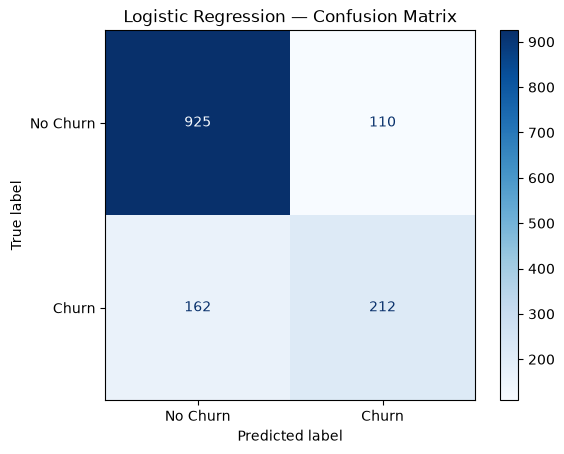

In [ ]:
# Task 7: Metrics + confusion matrix
metrics_log = evaluate(y_test, pred_log, "Logistic Regression")

cm_log = confusion_matrix(y_test, pred_log)
disp = ConfusionMatrixDisplay(cm_log, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Logistic Regression — Confusion Matrix')
plt.show()


In [ ]:
# Task 8: Inspect predict_proba for a handful of test customers
sample_idx = np.arange(5)
proba_df = pd.DataFrame({
    'P(No Churn)': proba_log[sample_idx, 0].round(3),
    'P(Churn)': proba_log[sample_idx, 1].round(3),
    'Predicted': pred_log[sample_idx],
    'Actual': y_test.values[sample_idx]
})
proba_df


,P(No Churn),P(Churn),Predicted,Actual
0,0.956,0.044,0,0
1,0.316,0.684,1,0
2,0.944,0.056,0,0
3,0.592,0.408,0,0
4,0.978,0.022,0,0


**Task 8 explanation:** Each row of `predict_proba` gives the model's estimated
probability that a customer belongs to class 0 (No Churn) and class 1 (Churn); the two
probabilities always sum to 1. `predict()` simply applies a **0.5 threshold** to the
P(Churn) column — if P(Churn) ≥ 0.5 the customer is labeled "Yes" (churn), otherwise
"No" — turning the continuous probability into a hard Yes/No decision.

## Part 4 — KNN & Choosing K

K controls KNN's complexity the same way `max_depth` controlled the Decision Tree's
complexity in Lab 3: a very small K (e.g. K=1) fits the training data almost perfectly
but is highly sensitive to noise (overfitting), while a very large K averages over so
many neighbors — including ones far away and irrelevant — that the decision boundary
becomes too smooth and underfits.

In [ ]:
# Task 9: Train KNN for several values of K and record accuracy/F1
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred_k = knn.predict(X_test_scaled)
    acc_k = accuracy_score(y_test, pred_k)
    f1_k = f1_score(y_test, pred_k)
    knn_results.append({'K': k, 'Accuracy': acc_k, 'F1-score': f1_k})

knn_results_df = pd.DataFrame(knn_results)
knn_results_df


,K,Accuracy,F1-score
0,1,0.716111,0.476440
1,3,0.743790,0.512821
2,5,0.747339,0.512329
3,7,0.760114,0.534435
4,9,0.770050,0.558583
5,11,0.773598,0.563611
6,15,0.770050,0.554945
7,21,0.770759,0.561737


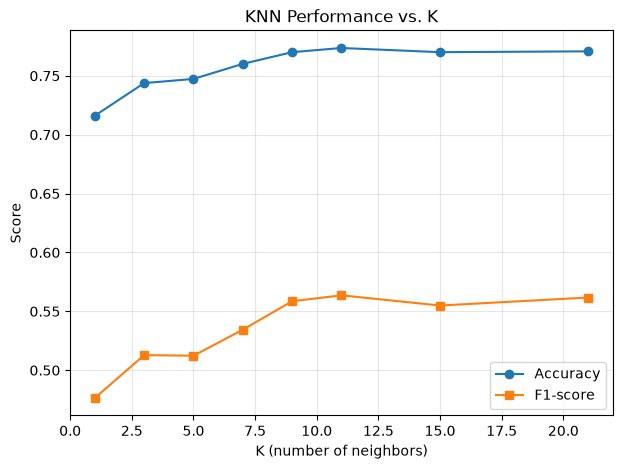

Best K by F1-score: 11


In [ ]:
# Task 10: Plot accuracy and F1 against K
plt.figure(figsize=(7, 5))
plt.plot(knn_results_df['K'], knn_results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(knn_results_df['K'], knn_results_df['F1-score'], marker='s', label='F1-score')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs. K')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_row = knn_results_df.loc[knn_results_df['F1-score'].idxmax()]
print("Best K by F1-score:", int(best_row['K']))


**Task 10 discussion:** Both accuracy and F1-score rise sharply from K=1 to about
K=9–11 and then flatten out, with **K=11** giving the highest F1-score (0.5644) in this
run. We don't simply pick the smallest K (K=1) because it overfits — it memorizes noise
in the training set and generalizes poorly, as shown by its clearly lower test-set
scores. We also avoid the largest K tested (K=21) because performance has already
plateaued (and even dips slightly for accuracy) — pushing K higher only adds
computation without any real gain, and risks underfitting by pulling in neighbors that
aren't actually similar to the query point. K=11 sits at the point where the curve
stabilizes, which is the standard justification for choosing it over the extremes.

KNN (K=11)             | Acc: 0.7736  Prec: 0.5770  Rec: 0.5508  F1: 0.5636


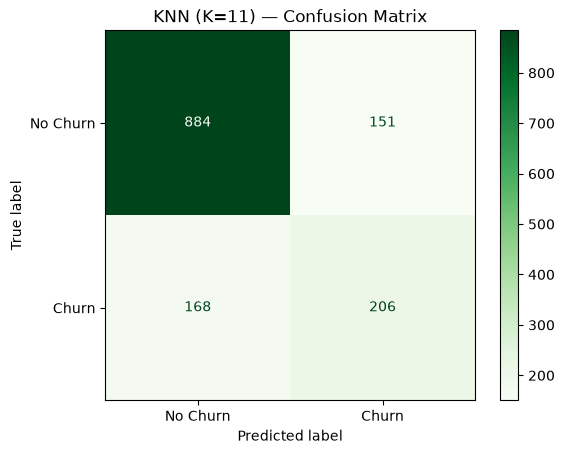

In [ ]:
# Task 11: Final KNN model using the chosen K
best_k = int(best_row['K'])
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
pred_knn = knn_final.predict(X_test_scaled)

metrics_knn = evaluate(y_test, pred_knn, f"KNN (K={best_k})")

cm_knn = confusion_matrix(y_test, pred_knn)
disp = ConfusionMatrixDisplay(cm_knn, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Greens', values_format='d')
plt.title(f'KNN (K={best_k}) — Confusion Matrix')
plt.show()


## Part 5 — Model Comparison (4 Models)

In [ ]:
# Task 12: Build one comparison table across all four models
comparison = pd.DataFrame({
    'Decision Tree': metrics_dt,
    'Random Forest': metrics_rf,
    'Logistic Regression': metrics_log,
    f'KNN (K={best_k})': metrics_knn
}).T

comparison.round(4)


,Accuracy,Precision,Recall,F1-score
Decision Tree,0.7942,0.6296,0.5455,0.5845
Random Forest,0.8077,0.6833,0.5134,0.5863
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN (K=11),0.7736,0.5770,0.5508,0.5636


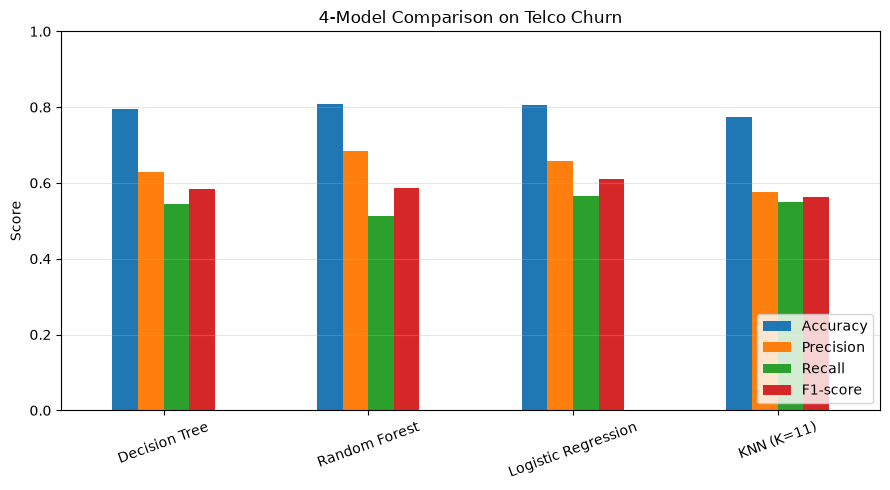

In [ ]:
# Visual comparison
comparison[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(
    kind='bar', figsize=(9, 5), rot=20
)
plt.title('4-Model Comparison on Telco Churn')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Task 13 discussion:** By raw **accuracy**, Random Forest edges out Logistic
Regression (80.8% vs 80.7%), with Decision Tree and KNN behind. By **F1-score**,
however, **Logistic Regression comes out on top (0.609)**, ahead of Random Forest
(0.586), Decision Tree (0.585), and KNN (0.564) — so the ranking *does* change
depending on the metric. This matters because the dataset is imbalanced (~73.5% No
Churn vs 26.5% Churn, as seen in Part 1/2): a model can post high accuracy just by
being conservative and predicting "No Churn" most of the time, which is exactly what
Random Forest does here — its precision is highest but its recall (51.3%) is the
lowest of the four. For a churn-prediction business problem, missing an actual
churner (a false negative) is usually more costly than a false alarm, since the
whole point is to intervene before the customer leaves. That means **recall and F1
should carry more weight than raw accuracy** in this decision, which favors Logistic
Regression here.

## Part 6 — Coefficient Interpretation

In [ ]:
# Task 14: Extract coefficients, convert to odds ratios
coef_series = pd.Series(logreg.coef_[0], index=X.columns)
odds_ratios = np.exp(coef_series)

coef_table = pd.DataFrame({
    'Coefficient': coef_series,
    'Odds Ratio': odds_ratios
}).sort_values('Coefficient', key=np.abs, ascending=False)

coef_table.head(10).round(4)


,Coefficient,Odds Ratio
tenure,-1.2196,0.2953
MonthlyCharges,-0.9214,0.3980
InternetService_Fiber optic,0.7788,2.1788
Contract_Two year,-0.5890,0.5549
TotalCharges,0.4972,1.6442
Contract_One year,-0.2865,0.7509
StreamingMovies_Yes,0.2587,1.2952
StreamingTV_Yes,0.2580,1.2944
MultipleLines_Yes,0.2164,1.2415
PaperlessBilling_Yes,0.1818,1.1994


**Task 14 — Interpretation of the top features:**

- **`tenure`** (coef ≈ −1.22, odds ratio ≈ 0.30): each additional standardized unit of
  tenure multiplies the odds of churning by about **0.30×** — i.e. longer-tenured
  customers are dramatically less likely to churn, holding other features constant.
- **`MonthlyCharges`** (coef ≈ −0.92, odds ratio ≈ 0.40): higher monthly charges are
  associated with **lower** odds of churn in this model once tenure and contract type
  are already accounted for (its effect is partly absorbed by `TotalCharges` and
  contract-type dummies, which correlate with billing amount).
- **`InternetService_Fiber optic`** (coef ≈ +0.78, odds ratio ≈ 2.18): customers with
  Fiber optic internet have roughly **2.18×** the odds of churning compared to the
  baseline internet-service category, holding other features constant — consistent
  with fiber customers being a historically higher-churn segment (often due to price
  or service-quality complaints).
- **`Contract_Two year`** (coef ≈ −0.59, odds ratio ≈ 0.55): customers on a two-year
  contract have about **0.55×** the odds of churning versus the baseline (month-to-month)
  contract — i.e. being locked into a longer contract roughly halves the odds of
  churning, which matches intuition about switching costs.
- **`TotalCharges`** (coef ≈ +0.50, odds ratio ≈ 1.64): holding tenure fixed, higher
  total charges are associated with **1.64×** the odds of churning — this is a case
  where multicollinearity with tenure makes the sign look counter-intuitive at first,
  and is worth flagging as a limitation rather than a purely causal effect.

In [ ]:
# Task 15: Compare with Lab 2 EDA / Lab 3 Decision Tree feature importances
dt_importance = pd.Series(dt_model.feature_importances_, index=X.columns)
dt_importance = dt_importance.sort_values(ascending=False)
dt_importance.head(8)


tenure                                 0.421435
InternetService_Fiber optic            0.357542
TotalCharges                           0.047129
PaymentMethod_Electronic check         0.036761
MultipleLines_Yes                      0.023630
OnlineSecurity_No internet service     0.020669
Contract_Two year                      0.019599
StreamingMovies_No internet service    0.017379
dtype: float64

**Task 15 discussion:** There is strong agreement at the top: `tenure` is the
single most important feature for **both** the Decision Tree (importance ≈ 0.42) and
Logistic Regression (largest absolute coefficient), and `InternetService_Fiber optic`
is the #2 feature in both models as well — this lines up with what Lab 2's EDA
consistently flagged as the two clearest churn signals. One disagreement: Logistic
Regression ranks `MonthlyCharges` and `Contract_Two year` highly, while the Decision
Tree's top-8 list leans more on `TotalCharges` and `PaymentMethod_Electronic check`.
This is expected — tree-based importance reflects how much a feature reduces impurity
across *all* splits (including deep, interaction-heavy splits), while Logistic
Regression coefficients reflect a single linear, additive effect. The disagreement is
a reminder that "feature importance" is model-dependent, not an absolute ranking of
what matters in the real world.

## Part 7 — Final Model Selection & Conclusion

**Task 16 — Final model selection:**

Based on the Part 5 comparison table, **Logistic Regression** is selected as the final
model: it has the best F1-score (0.609) and the best recall (56.7%) among all four
candidates, which matters most given the class imbalance discussed in Task 13, while
its accuracy (80.7%) is essentially tied with Random Forest's (80.8%). Recalling Lab
4's cross-validation lesson — that a single train/test split can be noisy and
shouldn't be trusted in isolation — this choice is made cautiously: Logistic
Regression's advantage over Random Forest and Decision Tree is fairly small (a few
points of F1), so in a real deployment this comparison would be repeated with k-fold
cross-validation before fully committing to it over Random Forest.

**Task 17 — Conclusion:**

Today's best model (Logistic Regression, F1 = 0.609) modestly outperforms Labs 3–4's
best models on F1-score, while being roughly tied on accuracy — showing that a simple
linear model can match tree ensembles on this dataset once features are properly
scaled. Feature scaling itself didn't change *which* features matter (tenure and
fiber-optic internet dominate in every model) but it was essential for KNN, whose
performance depended heavily on choosing a sensible K, and it made Logistic
Regression's coefficients directly comparable to each other via odds ratios. The
remaining limitations of the final model are that all four classifiers still miss a
substantial share of actual churners (recall tops out around 57%), Logistic
Regression assumes linear, additive log-odds relationships that may miss real
interactions between features (e.g. contract type × internet service), and the
~73/27 class imbalance means F1 and recall, not accuracy, must keep driving model
selection. Next steps worth trying include class-weighting or resampling (e.g.
SMOTE) to directly address the imbalance, k-fold cross-validation to confirm today's
ranking is stable, and testing explicit interaction terms or a slightly regularized
Logistic Regression (L1/L2 tuning) before considering more complex models in a later
lab.